# FIFA World Cup 2022: Group Stage Analysis

This project explores team performance in the 2022 FIFA World Cup
group stage using Python, Pandas, and Matplotlib.

The analysis focuses on:
- Goals scored and conceded
- Goal difference
- Scoring across groups
- Points and qualification outcomes

The dataset covers the group stage only.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

file_path = Path("data") / "Fifa World Cup Points Table.csv"

raw_df = pd.read_csv(file_path)
df = raw_df.copy()

df.head()

,Unnamed: 0,Teams,MP,W,D,L,GF,GA,+/-,Pts,Group
0,0,Netherlands (Q),3,2,1,0,5,1,4,7,A
1,1,Senegal (Q),3,2,0,1,4,3,1,6,A
2,2,Ecuador,3,1,1,1,4,3,1,4,A
3,3,Qatar,3,0,0,3,1,7,-6,0,A
4,4,England (Q),3,2,1,0,9,2,7,7,B


## Understanding the Dataset

Each row represents one team's group-stage performance.

| Column | Description |
|---|---|
| Teams | Team name; `(Q)` indicates qualification |
| MP | Matches played |
| W | Wins |
| D | Draws |
| L | Losses |
| GF | Goals scored |
| GA | Goals conceded |
| +/- | Goal difference |
| Pts | Points earned |
| Group | Group assignment |

In [10]:
print("Rows and columns:", df.shape)

display(df.head())
display(df.tail())

df.info()

Rows and columns: (32, 11)


,Unnamed: 0,Teams,MP,W,D,L,GF,GA,+/-,Pts,Group
0,0,Netherlands (Q),3,2,1,0,5,1,4,7,A
1,1,Senegal (Q),3,2,0,1,4,3,1,6,A
2,2,Ecuador,3,1,1,1,4,3,1,4,A
3,3,Qatar,3,0,0,3,1,7,-6,0,A
4,4,England (Q),3,2,1,0,9,2,7,7,B


,Unnamed: 0,Teams,MP,W,D,L,GF,GA,+/-,Pts,Group
27,27,Serbia,3,0,1,2,5,8,-3,1,G
28,28,Portugal (Q),3,2,0,1,6,4,2,6,H
29,29,South Korea (Q),3,1,1,1,4,4,0,4,H
30,30,Uruguay,3,1,1,1,2,2,0,4,H
31,31,Ghana,3,1,0,2,5,7,-2,3,H


<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  32 non-null     int64
 1   Teams       32 non-null     str  
 2   MP          32 non-null     int64
 3   W           32 non-null     int64
 4   D           32 non-null     int64
 5   L           32 non-null     int64
 6   GF          32 non-null     int64
 7   GA          32 non-null     int64
 8   +/-         32 non-null     int64
 9   Pts         32 non-null     int64
 10  Group       32 non-null     str  
dtypes: int64(9), str(2)
memory usage: 2.9 KB


In [11]:
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate team names:", df["Teams"].duplicated().sum())

Missing values:


Unnamed: 0    0
Teams         0
MP            0
W             0
D             0
L             0
GF            0
GA            0
+/-           0
Pts           0
Group         0
dtype: int64

Duplicate rows: 0
Duplicate team names: 0


## Data Cleaning

The cleaning process includes:
- Removing the exported index column
- Extracting qualification status from team names
- Standardizing column names
- Checking numerical consistency
- Applying and logging corrections

In [12]:
df = raw_df.copy()

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df["Qualified"] = df["Teams"].str.contains(
    r"\(Q\)", na=False
)

df["Teams"] = (
    df["Teams"]
    .str.replace(r"\s*\(Q\)", "", regex=True)
    .str.strip()
)

df = df.rename(columns={
    "Teams": "Team",
    "+/-": "GD"
})

df["Group"] = df["Group"].str.strip()

df.head()

,Team,MP,W,D,L,GF,GA,GD,Pts,Group,Qualified
0,Netherlands,3,2,1,0,5,1,4,7,A,True
1,Senegal,3,2,0,1,4,3,1,6,A,True
2,Ecuador,3,1,1,1,4,3,1,4,A,False
3,Qatar,3,0,0,3,1,7,-6,0,A,False
4,England,3,2,1,0,9,2,7,7,B,True


In [13]:
invalid_rows = df[
    (df["W"] + df["D"] + df["L"] != df["MP"])
    | (df["W"] * 3 + df["D"] != df["Pts"])
    | (df["GF"] - df["GA"] != df["GD"])
]

display(invalid_rows)

group_check = df.groupby("Group")[["GF", "GA"]].sum()
group_check["Difference"] = group_check["GF"] - group_check["GA"]

display(group_check)

,Team,MP,W,D,L,GF,GA,GD,Pts,Group,Qualified
11,Saudi Arabia,3,0,1,2,3,4,-1,3,C,False
13,Australia,3,2,0,1,6,4,-2,3,D,True
14,Tunisia,3,1,1,1,1,1,0,1,D,False
20,Morocco,3,3,1,0,4,1,3,7,F,True


,GF,GA,Difference
Group,,,
A,14,14,0
B,16,16,0
C,12,11,1
D,14,11,3
E,22,22,0
F,11,10,1
G,16,16,0
H,17,17,0


### Data Corrections

The original CSV contains inconsistent values.

The corrections below reproduce the correction set used in
the earlier analysis notebook. Each change is recorded in
a correction log.

Consistency checks confirm that the numerical relationships
hold after correction. They do not independently verify
the historical results; supporting sources should be documented.

In [14]:
corrections = {
    "Saudi Arabia": {"W": 1, "D": 0, "GA": 5, "GD": -2},
    "Australia": {"GF": 3, "GD": -1, "Pts": 6},
    "Tunisia": {"Pts": 4},
    "Morocco": {"W": 2},
    "Belgium": {"GA": 2, "GD": -1},
}

correction_log = []

for team, changes in corrections.items():
    mask = df["Team"].eq(team)

    for column, new_value in changes.items():
        old_value = df.loc[mask, column].iloc[0]

        if old_value != new_value:
            correction_log.append({
                "Team": team,
                "Column": column,
                "Old": old_value,
                "New": new_value
            })

            df.loc[mask, column] = new_value

correction_log = pd.DataFrame(
    correction_log,
    columns=["Team", "Column", "Old", "New"]
)

display(correction_log)

,Team,Column,Old,New
0,Saudi Arabia,W,0,1
1,Saudi Arabia,D,1,0
2,Saudi Arabia,GA,4,5
3,Saudi Arabia,GD,-1,-2
4,Australia,GF,6,3
5,Australia,GD,-2,-1
6,Australia,Pts,3,6
7,Tunisia,Pts,1,4
8,Morocco,W,3,2
9,Belgium,GA,1,2


In [15]:
assert len(df) == 32
assert df["Team"].is_unique
assert not df.isna().any().any()

assert (df["MP"] == 3).all()
assert (df["W"] + df["D"] + df["L"] == df["MP"]).all()
assert (df["W"] * 3 + df["D"] == df["Pts"]).all()
assert (df["GF"] - df["GA"] == df["GD"]).all()

group_check = df.groupby("Group")[["GF", "GA"]].sum()

assert (group_check["GF"] == group_check["GA"]).all()
assert df.groupby("Group").size().eq(4).all()
assert df.groupby("Group")["Qualified"].sum().eq(2).all()

print("PASS ALL: Data consistency checks passed.")

PASS ALL: Data consistency checks passed.


In [16]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

df.to_csv(output_dir / "worldcup_clean.csv", index=False)

correction_log.to_csv(
    output_dir / "corrections_log.csv",
    index=False
)

print("Files saved to:", output_dir.as_posix())

Files saved to: outputs


## Exploratory Data Analysis

This section summarizes team performance and the overall
scoring level before exploring specific questions.

In [17]:
numeric_columns = ["MP", "W", "D", "L", "GF", "GA", "GD", "Pts"]

display(df[numeric_columns].describe().round(2))

total_goals = int(df["GF"].sum())
total_matches = int(df["MP"].sum() / 2)
drawn_matches = int(df["D"].sum() / 2)

print("Teams:", df["Team"].nunique())
print("Groups:", df["Group"].nunique())
print("Matches:", total_matches)
print("Total goals:", total_goals)
print("Goals per match:", round(total_goals / total_matches, 2))
print("Drawn matches:", drawn_matches)

,MP,W,D,L,GF,GA,GD,Pts
count,32.0,32.00,32.00,32.00,32.00,32.00,32.00,32.00
mean,3.0,1.19,0.62,1.19,3.72,3.72,0.00,4.19
std,0.0,0.69,0.61,0.78,2.07,2.45,3.28,1.99
min,3.0,0.00,0.00,0.00,1.00,1.00,-8.00,0.00
25%,3.0,1.00,0.00,1.00,2.00,2.00,-2.00,3.00
50%,3.0,1.00,1.00,1.00,4.00,3.00,0.00,4.00
75%,3.0,2.00,1.00,2.00,5.00,5.00,2.00,6.00
max,3.0,2.00,2.00,3.00,9.00,11.00,7.00,7.00


Teams: 32
Groups: 8
Matches: 48
Total goals: 119
Goals per match: 2.48
Drawn matches: 10


The group stage included 32 teams across 8 groups.
A total of 119 goals were scored in 48 matches,
averaging 2.48 goals per match.

## Finding Answers with the Data

In [18]:
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

### 1. Which teams scored the most goals?

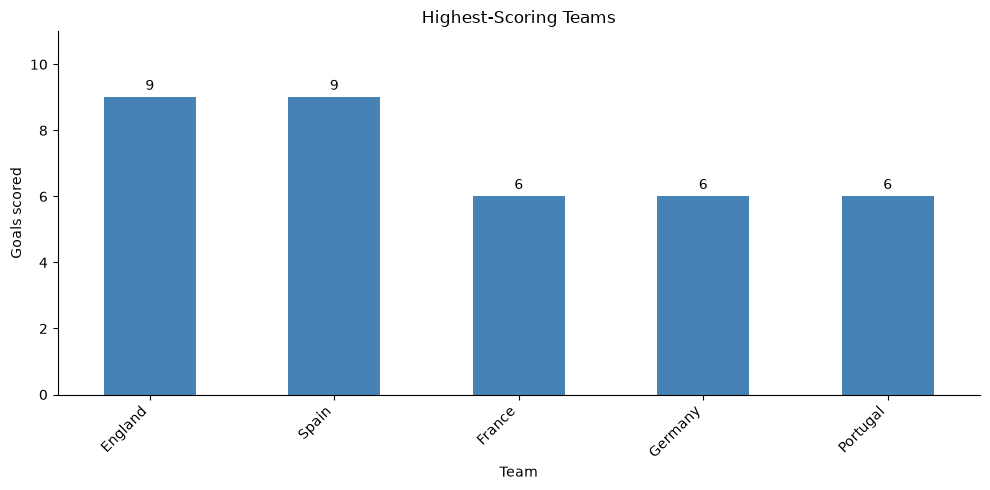

In [19]:
top_scorers = df.nlargest(5, "GF", keep="all")

ax = top_scorers.plot.bar(
    x="Team", y="GF", color="steelblue", legend=False
)

ax.bar_label(ax.containers[0], padding=3)
plt.title("Highest-Scoring Teams")
plt.xlabel("Team")
plt.ylabel("Goals scored")
plt.ylim(0, top_scorers["GF"].max() + 2)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

England and Spain were the highest-scoring teams,
with 9 goals each. France, Germany, and Portugal followed
with 6 goals each.

England earned 7 points, while Spain earned 4.
Scoring the same total number of goals did not produce
the same points total.

### 2. Which teams conceded the fewest goals?

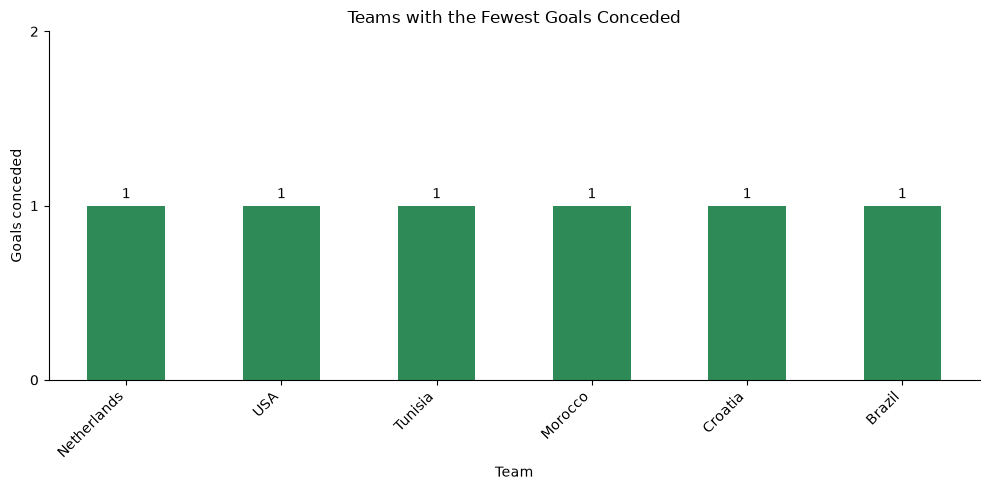

In [20]:
best_defenses = df.nsmallest(5, "GA", keep="all")

ax = best_defenses.plot.bar(
    x="Team", y="GA", color="seagreen", legend=False
)

ax.bar_label(ax.containers[0], padding=3)
plt.title("Teams with the Fewest Goals Conceded")
plt.xlabel("Team")
plt.ylabel("Goals conceded")
plt.ylim(0, 2)
plt.yticks([0, 1, 2])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Netherlands, USA, Tunisia, Morocco, Croatia, and Brazil
conceded only 1 goal each.

Tunisia was the only team among these six that did not qualify.
Conceding few goals did not guarantee qualification.

### 3. Which teams had the highest and lowest goal differences?

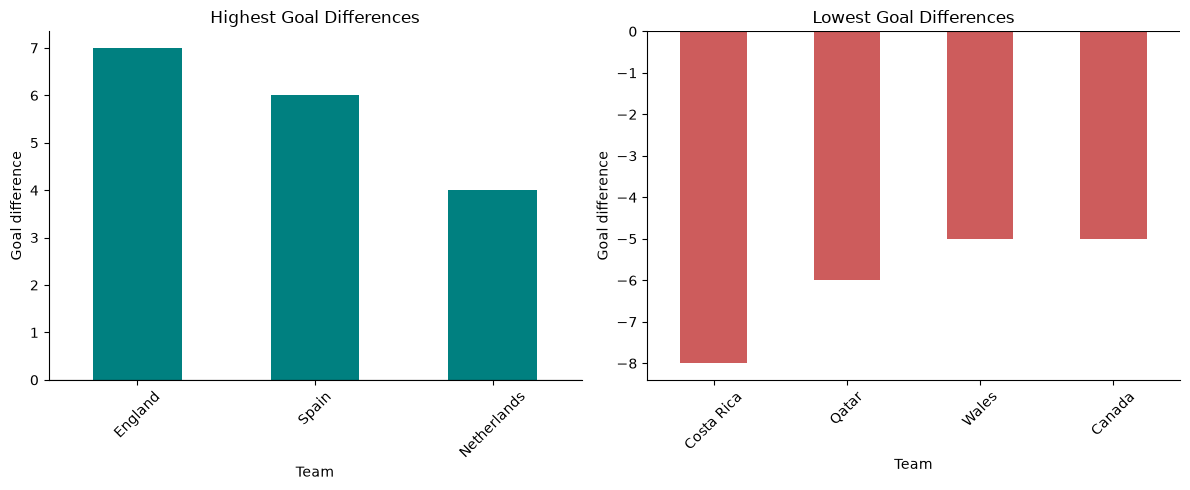

In [21]:
highest_gd = df.nlargest(3, "GD", keep="all")
lowest_gd = df.nsmallest(3, "GD", keep="all")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

highest_gd.plot.bar(
    x="Team", y="GD", ax=axes[0],
    color="teal", legend=False
)

lowest_gd.plot.bar(
    x="Team", y="GD", ax=axes[1],
    color="indianred", legend=False
)

axes[0].set_title("Highest Goal Differences")
axes[1].set_title("Lowest Goal Differences")

for ax in axes:
    ax.set_xlabel("Team")
    ax.set_ylabel("Goal difference")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

England had the highest goal difference at +7,
followed by Spain at +6 and Netherlands at +4.
All three teams qualified.

Costa Rica had the lowest goal difference at -8,
followed by Qatar at -6. Wales and Canada both finished at -5.
All four teams were eliminated.

### 4. Which group produced the most goals?

,Goals,Matches,Goals_per_match
Group,,,
A,14,6,2.33
B,16,6,2.67
C,12,6,2.00
D,11,6,1.83
E,22,6,3.67
F,11,6,1.83
G,16,6,2.67
H,17,6,2.83


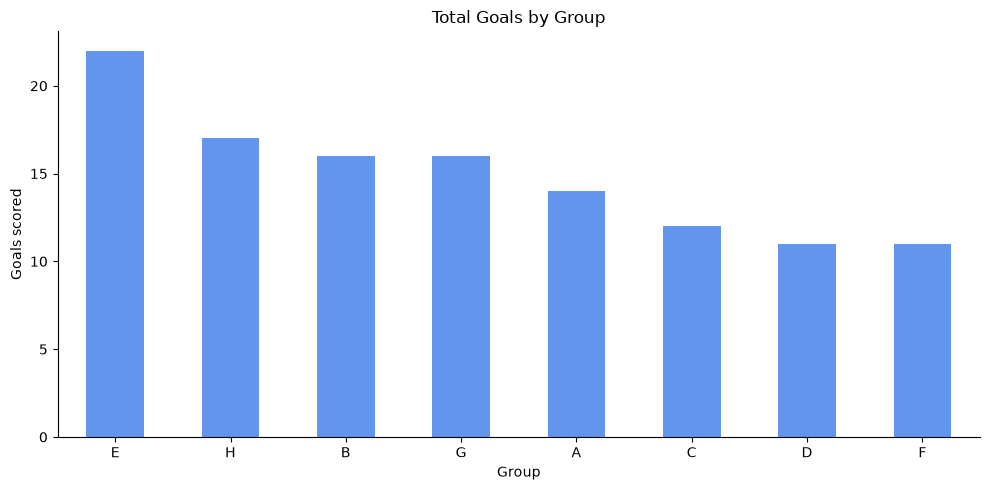

In [22]:
group_summary = df.groupby("Group").agg(
    Goals=("GF", "sum"),
    Team_match_appearances=("MP", "sum")
)

group_summary["Matches"] = (
    group_summary["Team_match_appearances"] / 2
).astype(int)

group_summary["Goals_per_match"] = (
    group_summary["Goals"] / group_summary["Matches"]
).round(2)

display(group_summary[["Goals", "Matches", "Goals_per_match"]])

group_summary["Goals"].sort_values(ascending=False).plot.bar(
    color="cornflowerblue"
)

plt.title("Total Goals by Group")
plt.xlabel("Group")
plt.ylabel("Goals scored")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Group E produced the most goals, with 22,
averaging 3.67 goals per match.

Groups D and F had the fewest goals, with 11 each,
averaging 1.83 goals per match.

Group E produced twice as many goals as either group.
These figures describe scoring volume, not group strength
or competitiveness.

### 5. What was the most common points total?

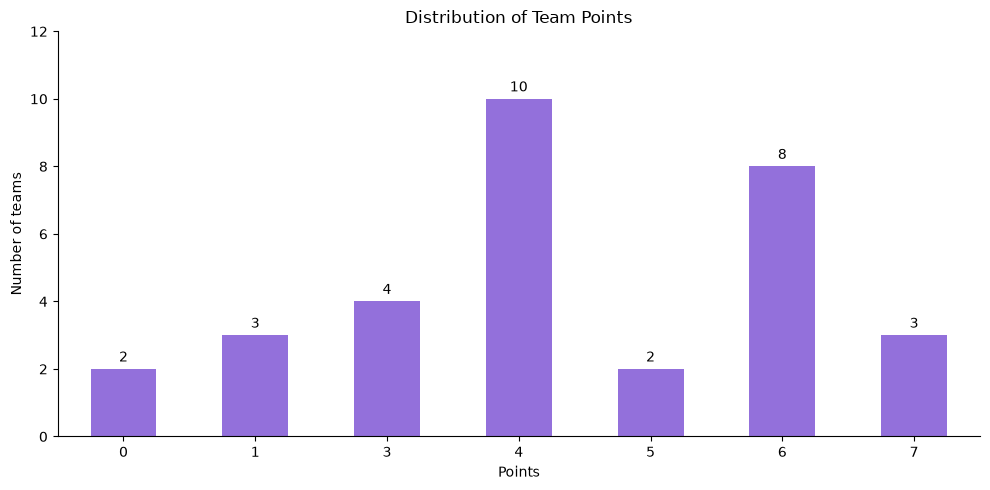

In [23]:
points_distribution = (
    df["Pts"].value_counts().sort_index()
)

ax = points_distribution.plot.bar(color="mediumpurple")

ax.bar_label(ax.containers[0], padding=3)
plt.title("Distribution of Team Points")
plt.xlabel("Points")
plt.ylabel("Number of teams")
plt.ylim(0, points_distribution.max() + 2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Four points was the most common total, achieved by 10 teams.
Six points was the next most common total, achieved by 8 teams.

Netherlands, England, and Morocco earned the highest total
of 7 points. No team won all three group matches.

### 6. Did four points guarantee qualification?

,Total_teams,Qualified,Eliminated,Qualification_rate_pct
Pts,,,,
0,2,0,2,0.0
1,3,0,3,0.0
3,4,0,4,0.0
4,10,3,7,30.0
5,2,2,0,100.0
6,8,8,0,100.0
7,3,3,0,100.0


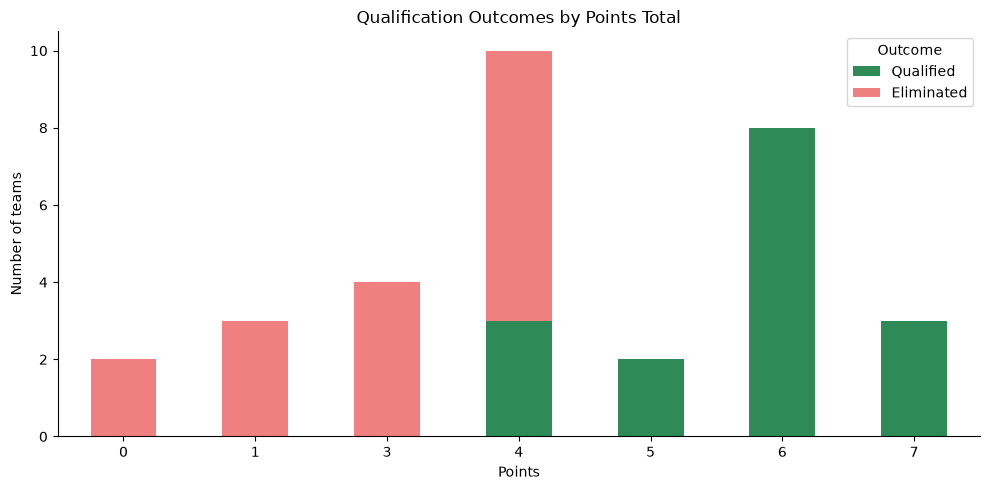

In [24]:
qualification = df.groupby("Pts").agg(
    Total_teams=("Team", "count"),
    Qualified=("Qualified", "sum")
)

qualification["Eliminated"] = (
    qualification["Total_teams"] - qualification["Qualified"]
)

qualification["Qualification_rate_pct"] = (
    qualification["Qualified"] / qualification["Total_teams"] * 100
).round(1)

display(qualification)

qualification[["Qualified", "Eliminated"]].plot.bar(
    stacked=True,
    color=["seagreen", "lightcoral"]
)

plt.title("Qualification Outcomes by Points Total")
plt.xlabel("Points")
plt.ylabel("Number of teams")
plt.xticks(rotation=0)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

Four points did not guarantee qualification.
Only 3 of the 10 teams with 4 points advanced:
Poland, Spain, and South Korea.

All 13 teams with at least 5 points qualified.
All 9 teams with 3 points or fewer were eliminated.

These are observed outcomes from this tournament,
not guaranteed qualification thresholds for future tournaments.

In [25]:
four_point_teams = df.loc[
    df["Pts"].eq(4),
    ["Team", "Group", "GF", "GA", "GD", "Pts", "Qualified"]
].sort_values(
    ["Qualified", "Group"],
    ascending=[False, True]
)

display(four_point_teams)

,Team,Group,GF,GA,GD,Pts,Qualified
9,Poland,C,2,2,0,4,True
17,Spain,E,9,3,6,4,True
29,South Korea,H,4,4,0,4,True
2,Ecuador,A,4,3,1,4,False
10,Mexico,C,2,3,-1,4,False
14,Tunisia,D,1,1,0,4,False
18,Germany,E,6,5,1,4,False
22,Belgium,F,1,2,-1,4,False
26,Cameroon,G,4,4,0,4,False
30,Uruguay,H,2,2,0,4,False


Teams with the same points total had different qualification
outcomes because they competed within different groups.

Qualification depended on each team's position in its group
and the applicable tiebreaking criteria, rather than a ranking
of all 32 teams together.

## Conclusion

- England and Spain scored the most goals, with 9 each.
- England had the highest goal difference at +7.
- Six teams conceded only 1 goal, but Tunisia did not qualify.
- Group E produced the most goals, with 22.
- Four points was the most common points total,
  but only 30% of teams with that total qualified.
- Every team with at least 5 points qualified in this tournament.

Goals scored, goals conceded, and points describe different
aspects of team performance. Qualification also needs to be
considered within the context of each group.

## Limitations

- The dataset covers the group stage only.
- Team totals do not show individual match results or
  how goals were distributed across matches.
- Group comparisons do not account for opponent strength.
- Findings describe this tournament and do not predict future outcomes.
- Corrections are logged, but their historical accuracy should
  be supported with documented external sources.